# Capstone Gate 4 (Part 1): Compare Models and Pick One
Goal: compare Logistic Regression, Decision Tree and Random Forest, then choose our final model.

In [1]:
# Import the libraries we need
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GroupKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score, f1_score, confusion_matrix

## Part A: Prepare the Data (same steps as Gate 3)

In [2]:
# Load the CSV file
df = pd.read_csv("athlete_recovery_synthetic.csv")

# Turn the score into a tier
def get_tier(score):
    if score >= 75:
        return "Green"
    elif score >= 40:
        return "Orange"
    else:
        return "Red"

df["Tier"] = df["Recovery_Score"].apply(get_tier)

# New columns
df["Sleep_Missing"] = df["Sleep_Duration_Hours"].isna().astype(int)
df["Stress_Num"] = df["Stress_Level"].map({"Low": 1, "Medium": 2, "High": 3})
df["Training_Load"] = df["Training_Duration_Min"] * df["Training_Intensity"]

In [3]:
# Inputs (X) and target (y)
features = ["Sleep_Duration_Hours", "Sleep_Missing", "Stress_Num", "HRV_ms",
            "Resting_Heart_Rate", "Muscle_Soreness", "Caffeine_Intake_mg",
            "Training_Duration_Min", "Training_Intensity", "Training_Load"]

X = df[features]
y = df["Tier"]

# Split by athlete: 80% train / 20% test
athlete_ids = df["Athlete_ID"].unique()
train_ids, test_ids = train_test_split(athlete_ids, test_size=0.2, random_state=42)

train_rows = df["Athlete_ID"].isin(train_ids)
X_train, y_train = X[train_rows], y[train_rows]
X_test, y_test = X[~train_rows], y[~train_rows]
groups_train = df.loc[train_rows, "Athlete_ID"]

# Fill missing values with the TRAIN medians
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Train rows:", len(X_train), "| Test rows:", len(X_test))

Train rows: 6705 | Test rows: 1674


## Part B: Compare the Models

**How we compare fairly:** we do NOT use the test set to choose. We use **cross-validation on the training athletes**: the training athletes are cut into 5 groups, and each group takes a turn as the "unseen" group. Athletes are never split across groups, so the scores are not too good to be true.

In [4]:
# A small helper: score a model with cross-validation and save the result
results = []

def check_model(name, model):
    pred = cross_val_predict(model, X_train, y_train, cv=GroupKFold(n_splits=5), groups=groups_train)
    red_recall = recall_score(y_train, pred, labels=["Red"], average=None)[0]
    macro_f1 = f1_score(y_train, pred, average="macro")
    results.append({"Model": name, "Red recall": round(red_recall, 3), "Macro F1": round(macro_f1, 3)})
    print(name, "| Red recall:", round(red_recall, 3), "| Macro F1:", round(macro_f1, 3))

In [5]:
# Logistic Regression
logreg = Pipeline([
    ("scale", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000))
])
check_model("Logistic Regression", logreg)

Logistic Regression | Red recall: 0.871 | Macro F1: 0.827


In [6]:
# Decision Tree: try a few depths (depth = how many questions the tree can ask)
for depth in [3, 5, 8]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    check_model(f"Decision Tree (depth {depth})", tree)

Decision Tree (depth 3) | Red recall: 0.739 | Macro F1: 0.726
Decision Tree (depth 5) | Red recall: 0.788 | Macro F1: 0.768
Decision Tree (depth 8) | Red recall: 0.833 | Macro F1: 0.774


In [7]:
# Random Forest: try a few depths (100 trees each)
for depth in [5, 8, 12]:
    forest = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=42)
    check_model(f"Random Forest (depth {depth})", forest)

Random Forest (depth 5) | Red recall: 0.832 | Macro F1: 0.796
Random Forest (depth 8) | Red recall: 0.837 | Macro F1: 0.804
Random Forest (depth 12) | Red recall: 0.848 | Macro F1: 0.811


In [8]:
# Compare all models, best Red recall first
compare = pd.DataFrame(results).sort_values(["Red recall", "Macro F1"], ascending=False)
print(compare)

                      Model  Red recall  Macro F1
0       Logistic Regression       0.871     0.827
6  Random Forest (depth 12)       0.848     0.811
5   Random Forest (depth 8)       0.837     0.804
3   Decision Tree (depth 8)       0.833     0.774
4   Random Forest (depth 5)       0.832     0.796
2   Decision Tree (depth 5)       0.788     0.768
1   Decision Tree (depth 3)       0.739     0.726


**Explain:** Which model is best, and why?

- **Logistic Regression is best** on both scores: Red recall about 0.87 and Macro F1 about 0.83 in cross-validation.
- **Random Forest (depth 12)** is close (0.85 and 0.81). The Decision Trees are lower, and the shallow ones are the weakest.
- Our rule from the charter is Red recall first, then Macro F1, so Logistic Regression wins. It is also the **simplest to explain** to a coach.
- Random Forest got better as we allowed deeper trees, so a deeper forest could get closer, but the gap is small.
- Careful: the data is synthetic, so we say "best on this dataset", not "best in general".

## Part C: Test the Chosen Model (once)

Now we use the test athletes, one time, only for the model we chose.

In [9]:
# Our chosen model (chosen from the table above)
final_model = Pipeline([
    ("scale", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000))
])
final_model.fit(X_train, y_train)

# Predict on the test athletes
pred = final_model.predict(X_test)

print("Red recall:", round(recall_score(y_test, pred, labels=["Red"], average=None)[0], 3))
print("Macro F1:  ", round(f1_score(y_test, pred, average="macro"), 3))

Red recall: 0.865
Macro F1:   0.836


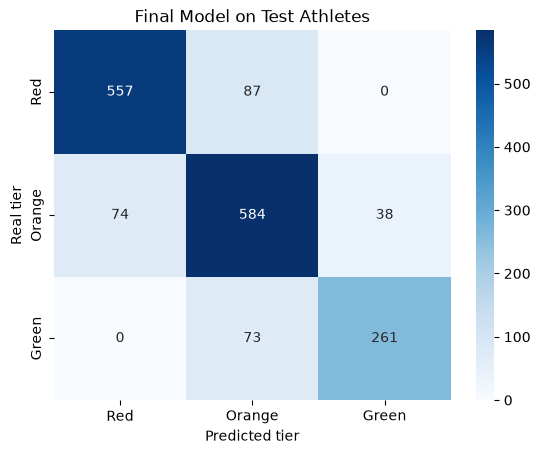

Real Red called Green: 0
Real Green called Red: 0


In [10]:
# Confusion matrix
order = ["Red", "Orange", "Green"]
cm = confusion_matrix(y_test, pred, labels=order)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=order, yticklabels=order)
plt.xlabel("Predicted tier")
plt.ylabel("Real tier")
plt.title("Final Model on Test Athletes")
plt.show()

# The most serious mistakes: real Red called Green, or real Green called Red
red_as_green = cm[0][2]
green_as_red = cm[2][0]
print("Real Red called Green:", red_as_green)
print("Real Green called Red:", green_as_red)

**Explain:** How does the final model compare with our Gate 3 baselines?

- On the test athletes, the final model gets Red recall about 0.87 and Macro F1 about 0.84. These are almost the same as in cross-validation (0.87 and 0.83), so it is not just memorizing the training data.
- It is much better than our other Gate 3 baselines: "always most common" (Red recall 0.00, Macro F1 0.20) and the simple rule (0.55 and 0.54).
- It made **0 mistakes** where a real Red day was called Green, or a real Green day was called Red. Its mistakes are between neighbouring tiers.
- Note: the final model is the same Logistic Regression we used as baseline 3 in Gate 3. It stayed the best after we compared the others.

## Part D: What Does the Model Use?

HRV_ms                  -3.20
Sleep_Duration_Hours    -1.75
Training_Intensity      -0.69
Training_Duration_Min   -0.10
Caffeine_Intake_mg       0.01
Training_Load            0.16
Resting_Heart_Rate       0.17
Sleep_Missing            0.29
Stress_Num               0.96
Muscle_Soreness          1.20
dtype: float64


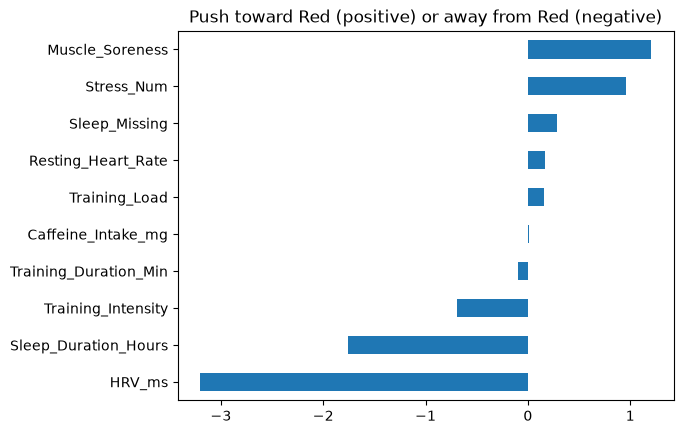

In [11]:
# Which inputs push a day toward Red? (the columns were put on the same scale)
red_position = list(final_model.classes_).index("Red")
coefs = final_model.named_steps["logreg"].coef_[red_position]

importance = pd.Series(coefs, index=features).sort_values()
print(importance.round(2))

importance.plot(kind="barh")
plt.title("Push toward Red (positive) or away from Red (negative)")
plt.show()

**Answer:** *What does the model use most?*

- **HRV** has by far the biggest effect: higher HRV pushes a day away from Red.
- **Sleep** is next: more sleep pushes away from Red.
- **Muscle soreness** and **stress** push toward Red.
- This matches what we found in the EDA.
- The three training columns (duration, intensity and load) are related to each other, so we should not read each one on its own. For example, intensity looks like it pushes away from Red, which is probably because of the overlap with training load.

## Part E: Save the Model

In [12]:
# Save the model, the input list and the medians, so the app can use them later
joblib.dump({"model": final_model, "features": features, "medians": medians},
            "readiness_model.joblib")
print("Saved readiness_model.joblib")

Saved readiness_model.joblib


## Summary (for the Gate 4 slide)

| Item | Result |
|---|---|
| Selected method | Logistic Regression |
| Why | Best cross-validation scores (Red recall 0.87, Macro F1 0.83) and the easiest to explain |
| Test result | Red recall 0.87, Macro F1 0.84, 0 Red/Green mix-ups |
| Compared with | Always most common (0.00 / 0.20), simple rule (0.55 / 0.54), Decision Tree and Random Forest |
| Validation plan | Split by athlete, fill missing values from train only, cross-validation by athlete, test set used once |
| Biggest inputs | HRV, sleep, muscle soreness, stress |
| Limitation | Synthetic data. We did not test predicting the score and then cutting it into tiers (optional extra) |